In [8]:
import pennylane as qp
import matplotlib.pyplot as plt

In [12]:
# Define functions

def prepare_entangled_pair():
    """Prepare Bell state |Φ+> = (|00> + |11>)/√2."""
    qp.Hadamard(wires=0)
    qp.CNOT(wires=[0, 1])


def encode_message(message):
    """"Encode bit message"""
    if message == "00":
        pass
    elif message == "01":
        qp.PauliX(wires=0)
    elif message == "10":
        qp.PauliZ(wires=0)
    elif message == "11":
        qp.PauliX(wires=0)
        qp.PauliZ(wires=0)


def decode_message():
    """Decode the message by applying CNOT and Hadamard gates."""
    qp.CNOT(wires=[0, 1])
    qp.Hadamard(wires=0)


def measure_message():
    """Measure the qubits to retrieve the message."""
    return qp.probs(wires=[0, 1])

In [13]:
superdense = qp.device("default.qubit", wires=2)

@qp.qnode(superdense)
def superdense_coding(message):
    """Perform superdense coding protocol."""
    prepare_entangled_pair()
    encode_message(message)
    decode_message()
    return measure_message()

In [17]:
for message in ("00", "01", "10", "11"):
    print(message, superdense_coding(message))

00 [1.00000000e+00 0.00000000e+00 5.00468047e-34 0.00000000e+00]
01 [0.00000000e+00 1.00000000e+00 0.00000000e+00 5.00468047e-34]
10 [5.00468047e-34 0.00000000e+00 1.00000000e+00 0.00000000e+00]
11 [0.00000000e+00 5.00468047e-34 0.00000000e+00 1.00000000e+00]


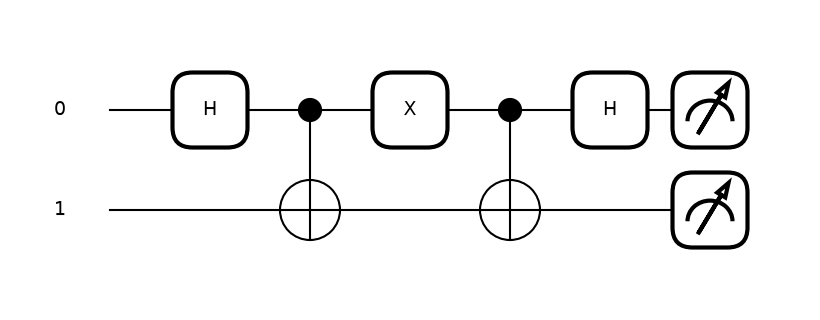

In [18]:
fig, ax = qp.draw_mpl(superdense_coding)("01")
plt.show()